# 12. Tutorial 12

**Course:** High Switching Frequency Power Converters

## 12.1 Averaged model of the buck

Buck $48~\mathrm{V} \to 12~\mathrm{V}$, $R = 1.44~\Omega$, $f_\mathrm{sw} = 1~\mathrm{MHz}$, $L = 2.2~\mu\mathrm{H}$, $C = 20~\mu\mathrm{F}$, $R_\mathrm{esr} = 2~\mathrm{m\Omega}$, $V_\mathrm{M} = 1~\mathrm{V}$, $H = 1$. The python-control package offers the same functions (`control.tf`, `control.bode`, `control.margin`); here numpy and scipy are used.

12.1.1 Import necessary modules (numpy as np, matplotlib.pyplot as plt, scipy.signal) and create the polynomials of $G_{vd}(s)$ and $Z_\mathrm{out}(s)$ with ESR, and a function `freq(num, den, f)` that evaluates a transfer function. Print $f_0$, $Q$, $Z_0$, $f_\mathrm{esr}$, $|G_{vd}(f_0)|$ and $|Z_\mathrm{out}(f_0)|$ and plot the Bode diagram of $G_{vd}$.


f0 = 23.99 kHz, Q = 4.34, Z0 = 332 mOhm, f_esr = 3.98 MHz
|Gvd(f0)| = 203 (46.2 dB), |Zout(f0)| = 1.40 Ohm


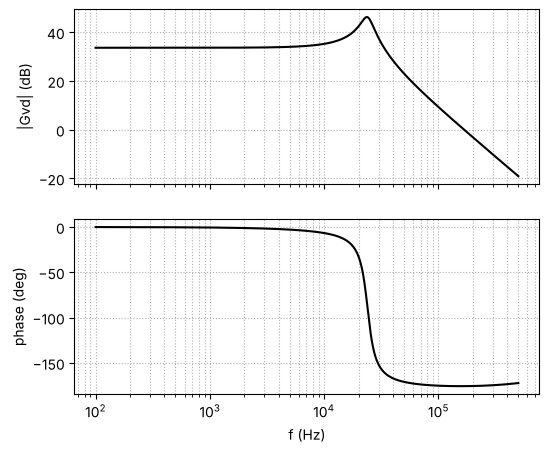

In [1]:
# Subtask 12.1.1 Import necessary modules and build the averaged model
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

Vin, Vo, fsw, L, C, Resr, R, VM = 48.0, 12.0, 1e6, 2.2e-6, 20e-6, 2e-3, 1.44, 1.0
den = [L * C * (R + Resr), L + R * Resr * C, R]            # common denominator
G_num = np.polymul([Vin * R], [Resr * C, 1])               # control to output, per unit duty
Z_num = np.polymul([L * R, 0], [Resr * C, 1])              # open-loop output impedance


def freq(num, den, f):
    s = 2j * np.pi * f
    return np.polyval(num, s) / np.polyval(den, s)


f0 = 1 / (2 * np.pi * np.sqrt(L * C))
print(f"f0 = {f0/1e3:.2f} kHz, Q = {R*np.sqrt(C/L):.2f}, Z0 = {np.sqrt(L/C)*1e3:.0f} mOhm, f_esr = {1/(2*np.pi*Resr*C)/1e6:.2f} MHz")
print(f"|Gvd(f0)| = {abs(freq(G_num, den, f0)):.0f} ({20*np.log10(abs(freq(G_num, den, f0))):.1f} dB), |Zout(f0)| = {abs(freq(Z_num, den, f0)):.2f} Ohm")
f = np.logspace(2, np.log10(5e5), 800)
G = freq(G_num, den, f)
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(6, 5))
ax[0].semilogx(f, 20 * np.log10(abs(G)), 'k'); ax[0].set_ylabel('|Gvd| (dB)'); ax[0].grid(True, which='both', ls=':')
ax[1].semilogx(f, np.unwrap(np.angle(G)) * 180 / np.pi, 'k'); ax[1].set_ylabel('phase (deg)'); ax[1].set_xlabel('f (Hz)')
ax[1].grid(True, which='both', ls=':'); plt.show()


## 12.2 Compensator and load step

12.2.1 Type III compensator with zeros at $0.8f_0$, poles at $f_\mathrm{sw}/2$; determine $\omega_\mathrm{I}$ for $f_\mathrm{c} = 100~\mathrm{kHz}$, the phase margin, and plot the loop gain.

12.2.2 Build the closed-loop output impedance $Z_\mathrm{out}/(1+T)$ with `scipy.signal.TransferFunction` and plot the output deviation for an $8~\mathrm{A}$ load step, open loop and closed loop.


omega_I = 7943 1/s; crossover and phase margin: [(np.float64(100.0), np.float64(50.5))]


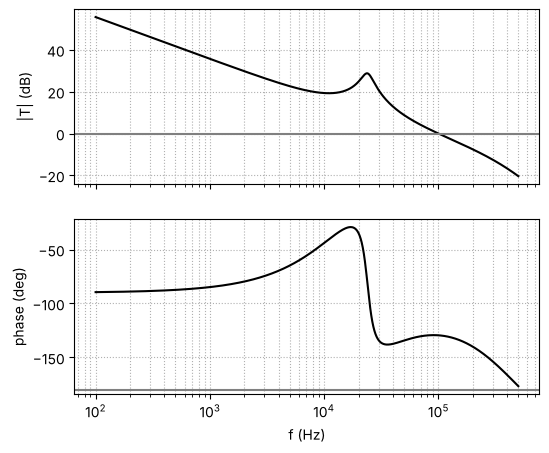

In [2]:
# Subtask 12.2.1 Type III compensator
fz, fp, fc = 0.8 * f0, fsw / 2, 1e5
wz, wp = 2 * np.pi * fz, 2 * np.pi * fp
Gc_num = np.polymul([1 / wz, 1], [1 / wz, 1])                      # without omega_I
Gc_den = np.polymul([1, 0], np.polymul([1 / wp, 1], [1 / wp, 1]))
T_shape = lambda f: freq(Gc_num, Gc_den, f) * freq(G_num, den, f) / VM
wI = 1 / abs(T_shape(fc))


def margins(Tf, f):
    mag, ph = np.abs(Tf), np.unwrap(np.angle(Tf)) * 180 / np.pi
    k = np.where((mag[:-1] >= 1) & (mag[1:] < 1))[0]
    return [(f[i], 180 + ph[i]) for i in k]


fs = np.logspace(2, 6, 20000)
print(f"omega_I = {wI:.4g} 1/s; crossover and phase margin: {[(round(a/1e3, 1), round(b, 1)) for a, b in margins(wI*T_shape(fs), fs)]}")
T = wI * T_shape(f)
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(6, 5))
ax[0].semilogx(f, 20 * np.log10(abs(T)), 'k'); ax[0].axhline(0, color='gray'); ax[0].set_ylabel('|T| (dB)'); ax[0].grid(True, which='both', ls=':')
ax[1].semilogx(f, np.unwrap(np.angle(T)) * 180 / np.pi, 'k'); ax[1].axhline(-180, color='gray'); ax[1].set_ylabel('phase (deg)')
ax[1].set_xlabel('f (Hz)'); ax[1].grid(True, which='both', ls=':'); plt.show()


8 A step: closed loop 0.52 V at 2.3 us, open loop 2.23 V; estimate 0.64 V; fc for 0.3 V: 212 kHz


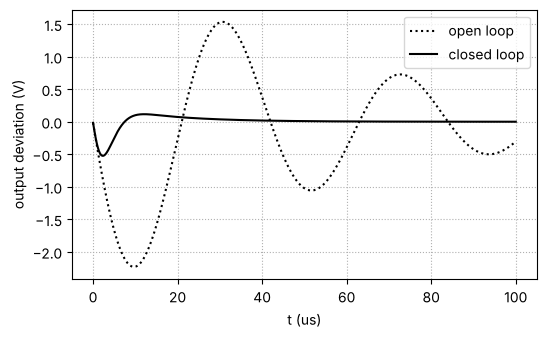

In [3]:
# Subtask 12.2.2 Load step
# polynomials with coefficients from 1e-20 to 1 are ill-conditioned: normalise s = wn p with wn = 2 pi 100 kHz
wn = 2 * np.pi * 1e5


def scale(poly):
    n = len(poly) - 1
    return np.array([c * wn**(n - i) for i, c in enumerate(poly)])


T_num = np.polymul(np.polymul([wI], Gc_num), G_num)
T_den = np.polymul(np.polymul(Gc_den, den), [VM])
Zcl = signal.TransferFunction(scale(np.polymul(Z_num, T_den)), scale(np.polymul(den, np.polyadd(T_den, T_num))))
Zol = signal.TransferFunction(scale(Z_num), scale(den))
t = np.linspace(0, 100e-6, 20000)
_, ycl = signal.step(Zcl, T=t * wn)      # time in units of 1/wn
_, yol = signal.step(Zol, T=t * wn)
print(f"8 A step: closed loop {8*ycl.max():.2f} V at {t[ycl.argmax()]*1e6:.1f} us, open loop {8*yol.max():.2f} V; "
      f"estimate {8/(2*np.pi*fc*C):.2f} V; fc for 0.3 V: {8/(2*np.pi*C*0.3)/1e3:.0f} kHz")
plt.figure(figsize=(6, 3.5))
plt.plot(t * 1e6, -8 * yol, 'k:', label='open loop'); plt.plot(t * 1e6, -8 * ycl, 'k', label='closed loop')
plt.xlabel('t (us)'); plt.ylabel('output deviation (V)'); plt.grid(True, ls=':'); plt.legend(); plt.show()


### 12.1 and 12.2 Solution

$f_0 = 24.0~\mathrm{kHz}$, $Q = 4.34$, $Z_0 = 332~\mathrm{m\Omega}$, $f_\mathrm{esr} = 3.98~\mathrm{MHz}$, $|G_{vd}(f_0)| = 203$ ($46.2~\mathrm{dB}$), $|Z_\mathrm{out}(f_0)| = 1.40~\Omega \approx R$. Type III: $\omega_\mathrm{I} = 7.9\cdot10^3~\mathrm{s^{-1}}$, $f_\mathrm{c} = 100~\mathrm{kHz}$, phase margin $50.5^\circ$. Load step $8~\mathrm{A}$: $0.52~\mathrm{V}$ closed loop (estimate $0.64~\mathrm{V}$), $2.2~\mathrm{V}$ open loop; $0.3~\mathrm{V}$ would need $212~\mathrm{kHz}$.


## 12.3 Delay

12.3.1 Add a delay $\mathrm{e}^{-sT_\mathrm{d}}$ with $T_\mathrm{d} = 1.5\,T_\mathrm{s}$ and print the phase margin at $100~\mathrm{kHz}$ and the largest delay for $30^\circ$.

12.3.2 Reduce $\omega_\mathrm{I}$ step by step (factor 0.1 to 1) and print crossover and phase margin with the delay. Plot the phase of the loop with and without delay.


In [4]:
# Subtask 12.3.1 Delay
Td = 1.5 / fsw
print("with 1.5 Ts:", [(round(a/1e3, 1), round(b, 1)) for a, b in margins(wI*T_shape(fs)*np.exp(-2j*np.pi*fs*Td), fs)])
pm0 = margins(wI * T_shape(fs), fs)[0][1]
print(f"delay for 30 deg: {(pm0 - 30)/(360*fc)*1e6:.2f} us")


with 1.5 Ts: [(np.float64(100.0), np.float64(-3.5))]
delay for 30 deg: 0.57 us


omega_I x 0.1: fc = 8.0 kHz, PM = 124.0 deg, fc = 30.6 kHz, PM = 28.3 deg
omega_I x 0.2: fc = 38.0 kHz, PM = 21.6 deg
omega_I x 0.3: fc = 45.4 kHz, PM = 19.7 deg
omega_I x 0.4: fc = 52.9 kHz, PM = 17.9 deg
omega_I x 0.5: fc = 60.5 kHz, PM = 15.5 deg
omega_I x 0.6: fc = 68.3 kHz, PM = 12.5 deg
omega_I x 0.7: fc = 76.2 kHz, PM = 9.1 deg
omega_I x 0.8: fc = 84.1 kHz, PM = 5.2 deg
omega_I x 0.9: fc = 92.1 kHz, PM = 1.0 deg
omega_I x 1.0: fc = 100.0 kHz, PM = -3.5 deg


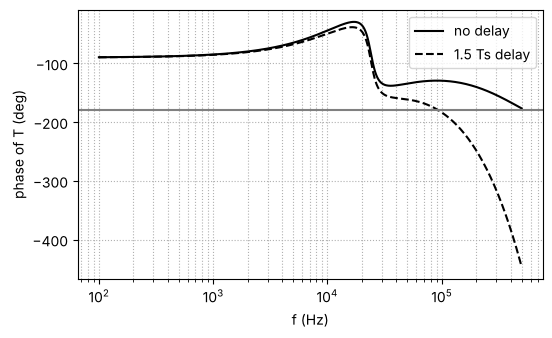

In [5]:
# Subtask 12.3.2 Lower crossover with delay
for k in np.linspace(0.1, 1.0, 10):
    m = margins(k * wI * T_shape(fs) * np.exp(-2j * np.pi * fs * Td), fs)
    print(f"omega_I x {k:.1f}: " + ", ".join(f"fc = {a/1e3:.1f} kHz, PM = {b:.1f} deg" for a, b in m))
Tdl = wI * T_shape(f) * np.exp(-2j * np.pi * f * Td)
plt.figure(figsize=(6, 3.5))
plt.semilogx(f, np.unwrap(np.angle(T)) * 180 / np.pi, 'k', label='no delay')
plt.semilogx(f, np.unwrap(np.angle(Tdl)) * 180 / np.pi, 'k--', label='1.5 Ts delay')
plt.axhline(-180, color='gray'); plt.xlabel('f (Hz)'); plt.ylabel('phase of T (deg)'); plt.grid(True, which='both', ls=':'); plt.legend(); plt.show()


### 12.3 Solution

The $1.5\,T_\mathrm{s}$ delay costs $54^\circ$ at $100~\mathrm{kHz}$: phase margin $-3.5^\circ$. $30^\circ$ allow $0.57~\mu\mathrm{s}$. Lowering $\omega_\mathrm{I}$ moves the crossover towards $f_0$, where the phase is lower still: the margin does not exceed $28^\circ$ between $30$ and $100~\mathrm{kHz}$. Reduce the delay or use an inner current loop.


## 12.4 Current mode and constant on-time

12.4.1 Peak current mode, buck $12 \to 7.2~\mathrm{V}$, $L = 2.2~\mu\mathrm{H}$, $1~\mathrm{MHz}$, $i_\mathrm{c} = 5~\mathrm{A}$: create `simulate_pcm(ma, n, di0)` (cycle-by-cycle, on-time limited to 95 %) and plot the inductor current for $m_\mathrm{a} = 0$, $m_2/2$, $m_2$ after a valley perturbation of $0.15~\mathrm{A}$. Print the perturbation factors and $Q_\mathrm{p}$.

12.4.2 Constant on-time: plot $f_\mathrm{sw}$ versus $V_\mathrm{in}$ ($36 \ldots 60~\mathrm{V}$) for fixed $t_\mathrm{on} = 250~\mathrm{ns}$ and for adaptive $t_\mathrm{on} = V_\mathrm{out}/(V_\mathrm{in}f_\mathrm{set})$.


ma = 0: factor -1.50, Qp = inf
ma = m2/2: factor -0.43, Qp = 1.59
ma = m2: factor -0.00, Qp = 0.64


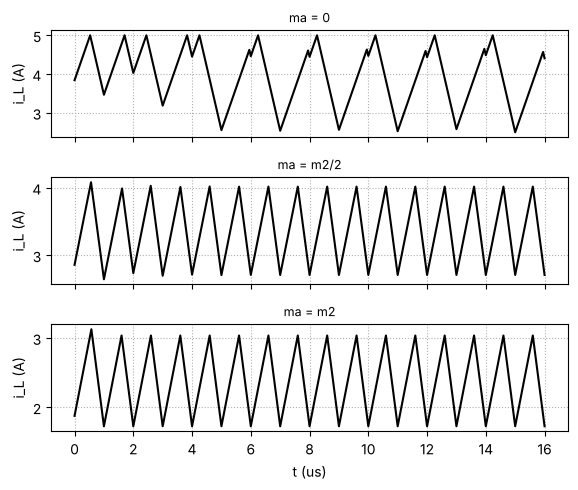

m1 = 2.18 A/us, m2 = 3.27 A/us


In [6]:
# Subtask 12.4.1 Peak current mode with slope compensation
Vin2, Vo2, L2, T2, Ic = 12.0, 7.2, 2.2e-6, 1e-6, 5.0
m1, m2 = (Vin2 - Vo2) / L2, Vo2 / L2
D = Vo2 / Vin2


def simulate_pcm(ma, n=16, di0=0.15):
    i = Ic - (m1 + ma) * D * T2 + di0          # perturbed valley current
    pts = [(0.0, i)]
    for k in range(n):
        ton = min(max((Ic - i) / (m1 + ma), 0.0), 0.95 * T2)
        ip = i + m1 * ton
        pts.append((k * T2 + ton, ip))
        i = ip - m2 * (T2 - ton)
        pts.append(((k + 1) * T2, i))
    return np.array(pts)


fig, ax = plt.subplots(3, 1, sharex=True, figsize=(6, 5))
for a, (ma, name) in zip(ax, ((0.0, 'ma = 0'), (m2 / 2, 'ma = m2/2'), (m2, 'ma = m2'))):
    p = simulate_pcm(ma)
    mc = 1 + ma / m1
    Qp = 1 / (np.pi * (mc * (1 - D) - 0.5)) if mc * (1 - D) > 0.5 else np.inf
    print(f"{name}: factor {-(m2 - ma)/(m1 + ma):.2f}, Qp = {Qp:.2f}")
    a.plot(p[:, 0] * 1e6, p[:, 1], 'k'); a.set_ylabel('i_L (A)'); a.set_title(name, fontsize=9); a.grid(True, ls=':')
ax[-1].set_xlabel('t (us)'); plt.tight_layout(); plt.show()
print(f"m1 = {m1/1e6:.2f} A/us, m2 = {m2/1e6:.2f} A/us")


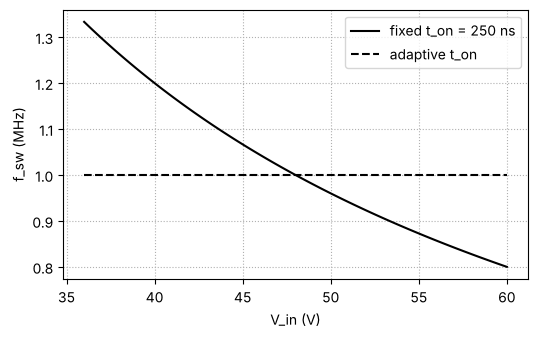

V_in = 36 V: f_sw = 1.33 MHz (fixed), t_on = 333 ns (adaptive)
V_in = 48 V: f_sw = 1.00 MHz (fixed), t_on = 250 ns (adaptive)
V_in = 60 V: f_sw = 0.80 MHz (fixed), t_on = 200 ns (adaptive)


In [7]:
# Subtask 12.4.2 Constant on-time
V = np.linspace(36, 60, 100)
ton = Vo / (Vin * fsw)
plt.figure(figsize=(6, 3.5))
plt.plot(V, Vo / (V * ton) / 1e6, 'k', label='fixed t_on = 250 ns')
plt.plot(V, np.full_like(V, fsw / 1e6), 'k--', label='adaptive t_on')
plt.xlabel('V_in (V)'); plt.ylabel('f_sw (MHz)'); plt.grid(True, ls=':'); plt.legend(); plt.show()
for v in (36, 48, 60):
    print(f"V_in = {v} V: f_sw = {Vo/(v*ton)/1e6:.2f} MHz (fixed), t_on = {Vo/(v*fsw)*1e9:.0f} ns (adaptive)")


### 12.4 Solution

$m_1 = 2.18~\mathrm{A/\mu s}$, $m_2 = 3.27~\mathrm{A/\mu s}$. Without ramp the perturbation grows by $-1.5$ per period until the on-time limit holds a period-two oscillation; with $m_2/2$ it decays by $-0.43$ ($Q_\mathrm{p} = 1.59$); with $m_2$ it vanishes in one period ($Q_\mathrm{p} = 0.64$). Constant on-time: $1.33$, $1.00$ and $0.80~\mathrm{MHz}$ at $36$, $48$ and $60~\mathrm{V}$; adaptive on-time ($333$, $250$, $200~\mathrm{ns}$) keeps $1~\mathrm{MHz}$.
